In [6]:
# --- Allgemeine Werkzeuge ---
import numpy as np                  # Rechnen mit Zahlenlisten/Tabellen ("np" = Abkürzung)
import torch                        # PyTorch: Bibliothek für neuronale Netze
import torch.nn as nn               # Bausteine für Netze (Schichten, Aktivierungen, Loss)
import matplotlib.pyplot as plt     # Zum Zeichnen von Grafiken/Plots
from sklearn.datasets import make_moons  # Erzeugt den Two-Moons-Datensatz

# --- probly: die drei Schritte ---
from probly.method import dropout             # 1. Netz umbauen -> Dropout-Modell mit Unsicherheit
from probly.representer import representer    # 2. Modell mehrfach vorhersagen lassen, Ergebnisse sammeln
from probly.quantification import decompose   # 3. Daraus Unsicherheit berechnen (total/aleatorisch/epistemisch)

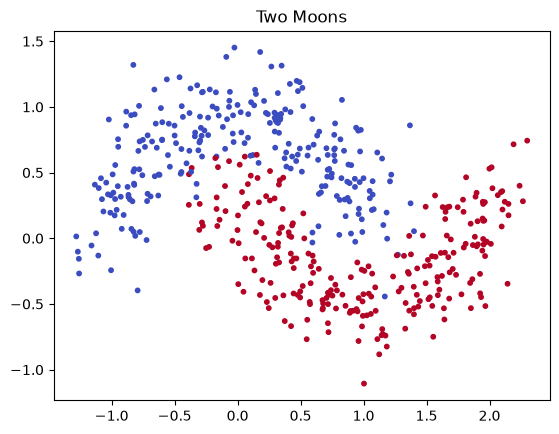

In [5]:
# --- Datensatz erzeugen ---
# n_samples=500: 500 Punkte insgesamt
# noise=0.2: Punkte werden verwackelt, die Monde überlappen leicht -> sorgt für aleatorische Unsicherheit
# random_state=0: fester Zufall, damit bei jedem Ausführen dieselben Daten rauskommen
X_np, y_np = make_moons(n_samples=500, noise=0.2, random_state=0)

# X_np: die Koordinaten der Punkte, Form (500, 2) -> jede Zeile = ein Punkt mit x und y
# y_np: die Klasse jedes Punkts, 0 = oberer Mond, 1 = unterer Mond

# --- In PyTorch-Format umwandeln ---
# Das Netz arbeitet mit "Tensoren" statt mit numpy-Arrays (ähnlich, aber für PyTorch)
X = torch.tensor(X_np, dtype=torch.float32)   # Koordinaten als Kommazahlen
y = torch.tensor(y_np, dtype=torch.long)      # Klassen als ganze Zahlen (so will es PyTorch)

# --- Plotten ---
# Jeder Punkt wird an seine (x, y)-Position gezeichnet, Farbe = Klasse
plt.scatter(X_np[:, 0], X_np[:, 1], c=y_np, cmap="coolwarm", s=10)
# X_np[:, 0] = alle x-Werte, X_np[:, 1] = alle y-Werte
# c=y_np: Farbe nach Klasse, cmap: Farbschema (blau/rot), s=10: Punktgröße
plt.title("Two Moons")
plt.show()

In [7]:
# --- 1. Ein ganz normales neuronales Netz bauen ---
# nn.Sequential = Schichten werden der Reihe nach durchlaufen
net = nn.Sequential(
    nn.Linear(2, 64),    # Eingabe: 2 Zahlen (x, y) -> 64 Neuronen
    nn.ReLU(),           # Aktivierung: macht das Netz "nicht-linear", damit es Kurven lernen kann
    nn.Linear(64, 64),   # zweite Schicht: 64 -> 64 Neuronen
    nn.ReLU(),
    nn.Linear(64, 2),    # Ausgabe: 2 Zahlen = eine Bewertung pro Klasse (oberer/unterer Mond)
)

# --- 2. probly: Netz zum Dropout-Modell umbauen ---
# p=0.25: bei jeder Vorhersage werden zufällig 25 % der Neuronen ausgeschaltet
# predictor_type="logit_classifier": sagt probly, dass das Netz Klassen-Bewertungen
#   (sogenannte Logits) ausgibt, aus denen später Wahrscheinlichkeiten werden
model = dropout(net, p=0.25, predictor_type="logit_classifier")

# --- 3. Trainieren ---
# Adam = Optimierer, der die Parameter des Netzes anpasst; lr = Lernrate (Schrittgröße)
opt = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(500):                     # 500 Trainingsrunden über alle Daten
    opt.zero_grad()                          # alte Rechenergebnisse vom letzten Schritt löschen
    logits = model(X)                        # Vorhersage für alle 500 Punkte
    loss = nn.functional.cross_entropy(logits, y)  # Fehler: wie falsch liegt das Modell?
    loss.backward()                          # berechnen, in welche Richtung die Parameter sich ändern sollen
    opt.step()                               # Parameter einen Schritt in diese Richtung anpassen

    if epoch % 100 == 0:                     # alle 100 Runden den Fehler ausgeben
        print(f"Runde {epoch}: Loss = {loss.item():.3f}")

print(f"Fertig. Loss am Ende: {loss.item():.3f}")

Runde 0: Loss = 0.733
Runde 100: Loss = 0.100
Runde 200: Loss = 0.063
Runde 300: Loss = 0.049
Runde 400: Loss = 0.051
Fertig. Loss am Ende: 0.051


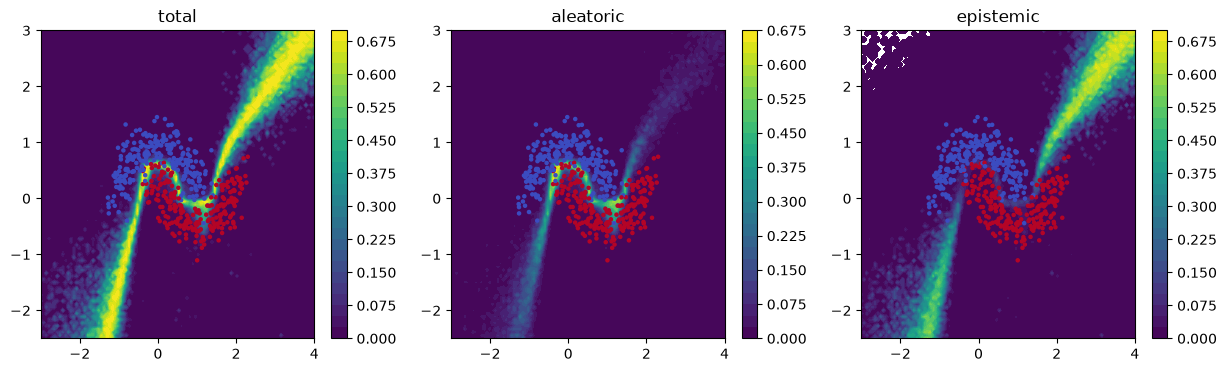

In [10]:
# --- 1. Ein Gitter über die ganze Fläche legen ---
# Wir wollen nicht nur an den 500 Datenpunkten wissen, wie unsicher das Modell ist,
# sondern ÜBERALL -> also auch weit weg von den Daten (dort erwarten wir epistemische Unsicherheit)
# linspace(-3, 4, 100): 100 gleichmäßig verteilte x-Werte von -3 bis 4 (größer als die Daten!)
xx, yy = np.meshgrid(np.linspace(-3, 4, 100), np.linspace(-2.5, 3, 100))
# meshgrid macht daraus ein 100x100-Gitter = 10.000 Punkte

# Gitterpunkte als Liste von (x, y)-Paaren, Form (10000, 2), dann in Tensor umwandeln
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

# --- 2. probly: Modell 50-mal vorhersagen lassen ---
# Jedes Mal sind andere 25 % der Neuronen aus -> 50 leicht unterschiedliche Vorhersagen pro Punkt
rep = representer(model, num_samples=50)
out = rep.represent(grid)

# --- 3. probly: Unsicherheit berechnen und aufteilen ---
# total     = wie unsicher insgesamt (Entropie der gemittelten Vorhersage)
# aleatoric = Rauschen: auch die einzelnen Vorhersagen sind sich unsicher (Mittel der Entropien)
# epistemic = Wissenslücke: die 50 Vorhersagen sind sich UNEINIG (Differenz der beiden)
unc = decompose(out)

# --- 4. Drei Karten nebeneinander zeichnen ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))       # 1 Zeile, 3 Bilder
for ax, name in zip(axes, ["total", "aleatoric", "epistemic"]):
    werte = getattr(unc, name)                        # holt unc.total / unc.aleatoric / unc.epistemic
    werte = werte.detach().numpy().reshape(xx.shape)  # Tensor -> numpy, zurück in 100x100-Form
    im = ax.contourf(xx, yy, werte, levels=30, cmap="viridis")  # Farbkarte: hell = unsicher
    ax.scatter(X_np[:, 0], X_np[:, 1], c=y_np, cmap="coolwarm", s=5)  # Datenpunkte obendrauf
    ax.set_title(name)
    fig.colorbar(im, ax=ax)                           # Farbskala daneben
plt.show()

Netz 0: Loss am Ende = 0.030
Netz 1: Loss am Ende = 0.026
Netz 2: Loss am Ende = 0.035
Netz 3: Loss am Ende = 0.028
Netz 4: Loss am Ende = 0.030


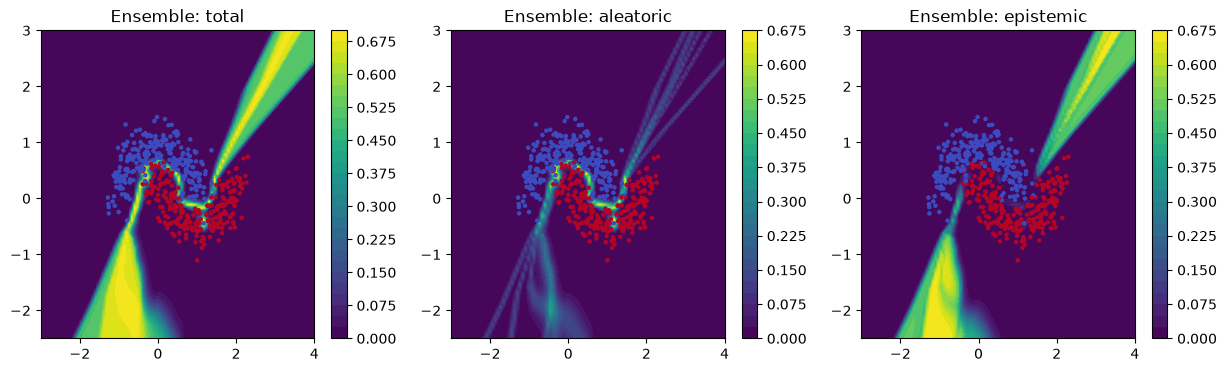

In [11]:
from probly.method import ensemble

# --- 1. Gleiches Netz wie vorher, aber ohne Dropout ---
net2 = nn.Sequential(
    nn.Linear(2, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 2),
)

# --- 2. probly: daraus ein Ensemble aus 5 Netzen machen ---
# num_members=5: 5 unabhängige Kopien des Netzes
# reset_params=True: jede Kopie startet mit anderen Zufallswerten -> sie lernen leicht unterschiedlich
ens = ensemble(net2, num_members=5, reset_params=True, predictor_type="logit_classifier")

# --- 3. Jedes der 5 Netze einzeln trainieren (gleiche Schleife wie vorher) ---
for i, member in enumerate(ens):
    opt = torch.optim.Adam(member.parameters(), lr=0.01)
    for epoch in range(500):
        opt.zero_grad()
        loss = nn.functional.cross_entropy(member(X), y)
        loss.backward()
        opt.step()
    print(f"Netz {i}: Loss am Ende = {loss.item():.3f}")

# --- 4. Unsicherheit berechnen ---
# Kein num_samples nötig: Die 5 Netze liefern automatisch 5 Vorhersagen pro Punkt
rep_ens = representer(ens)
out_ens = rep_ens.represent(grid)     # dasselbe Gitter wie in Zelle 4
unc_ens = decompose(out_ens)

# --- 5. Plotten (wie in Zelle 4) ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ["total", "aleatoric", "epistemic"]):
    werte = getattr(unc_ens, name).detach().numpy().clip(min=0).reshape(xx.shape)
    im = ax.contourf(xx, yy, werte, levels=30, cmap="viridis")
    ax.scatter(X_np[:, 0], X_np[:, 1], c=y_np, cmap="coolwarm", s=5)
    ax.set_title(f"Ensemble: {name}")
    fig.colorbar(im, ax=ax)
plt.show()

In [15]:
import shapiq

# --- 1. Zwei interessante Punkte automatisch aus dem Gitter suchen ---
idx_alea = unc_ens.aleatoric.argmax().item()   # Punkt mit der höchsten aleatorischen Unsicherheit
idx_epi  = unc_ens.epistemic.argmax().item()   # Punkt mit der höchsten epistemischen Unsicherheit
punkt_alea = grid[idx_alea]
punkt_epi  = grid[idx_epi]
print("Aleatorischer Punkt:", punkt_alea.numpy())
print("Epistemischer Punkt:", punkt_epi.numpy())

# --- 2. Wie "entfernt" man ein Merkmal? ---
# Einfachste Variante: fehlendes Merkmal durch den Durchschnitt der Trainingsdaten ersetzen
mittelwert = X.mean(dim=0)

# --- 3. Die Wertfunktion v(S): Unsicherheit, wenn nur die Merkmale in S bekannt sind ---
def unsicherheit(punkt, bekannt, art):
    x = mittelwert.clone()               # erst alles auf Durchschnitt setzen
    for j in bekannt:                    # dann die bekannten Merkmale vom echten Punkt übernehmen
        x[j] = punkt[j]
    out = rep_ens.represent(x.unsqueeze(0))        # Ensemble vorhersagen lassen (1 Punkt)
    return getattr(decompose(out), art).item()     # gewünschte Unsicherheit als Zahl

# --- 4. Daraus ein shapiq-Game machen ---
class UnsicherheitsGame(shapiq.Game):
    def __init__(self, punkt, art):
        self.punkt, self.art = punkt, art
        super().__init__(n_players=2, normalize=False)   # 2 Spieler = Merkmal x und Merkmal y

    def value_function(self, coalitions):
        # shapiq gibt uns Koalitionen wie [True, False] = "nur x bekannt"
        # wir geben für jede die Unsicherheit zurück
        return np.array([
            unsicherheit(self.punkt, [j for j in range(2) if c[j]], self.art)
            for c in coalitions
        ])

# --- 5. Shapley-Werte berechnen und ausgeben ---
for name, punkt in [("aleatorischer Punkt", punkt_alea), ("epistemischer Punkt", punkt_epi)]:
    print(f"\n=== {name} ===")
    for art in ["total", "aleatoric", "epistemic"]:
        game = UnsicherheitsGame(punkt, art)
        computer = shapiq.ExactComputer(game=game, n_players=2)  # exakte Berechnung bei 2 Merkmalen
        sv = computer("SV", order=1)                              # SV = Shapley Values
        print(f"{art:10s}  x: {sv[(0,)]:+.3f}   y: {sv[(1,)]:+.3f}")

Aleatorischer Punkt: [0.25252524 0.5555556 ]
Epistemischer Punkt: [-1.2323233 -2.5      ]

=== aleatorischer Punkt ===
total       x: +0.274   y: +0.276
aleatoric   x: +0.266   y: +0.269
epistemic   x: +0.007   y: +0.007

=== epistemischer Punkt ===
total       x: +0.202   y: +0.333
aleatoric   x: -0.109   y: -0.026
epistemic   x: +0.310   y: +0.358
